# BRISC 2025 — Brain Tumor Classification

A reproducible image-classification baseline for the **BRISC 2025** dataset. This notebook explores the data, trains a small CNN baseline and a transfer-learning model (ResNet18), compares them on validation data, and evaluates the selected models on the official test split once, after removing training images that duplicate test images.

**Classes:** glioma, meningioma, no tumor, and pituitary tumor. The input files are 2D contrast-enhanced T1-weighted MRI images.

**Dataset:** [BRISC 2025 on Kaggle](https://www.kaggle.com/datasets/briscdataset/brisc2025/data) · [Dataset paper](https://www.nature.com/articles/s41597-026-06753-y)

## 1. Environment and dataset

The code supports Kaggle Notebook or Colab with a GPU. `kagglehub` downloads the public dataset, and the path resolver handles either a dataset root or a nested `brisc2025/` directory. If the pretrained ResNet18 weights are not cached, internet access is needed to download them.

In [ ]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # deterministic CUDA matmuls (must be set before torch is used)
from pathlib import Path
from collections import Counter, defaultdict
import random
import time
import copy
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

import kagglehub
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision import transforms, models

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from tqdm import tqdm
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)

SEED = 42
CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
IMG_SIZE = 128
CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)
BATCH_SIZE = 32
NUM_WORKERS = 0 if os.name == "nt" else 2


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id):
    # Seed Python and NumPy independently in each DataLoader worker.
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


# Make GPU training repeatable.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


def has_dataset_layout(path: Path) -> bool:
    return (path / "classification_task" / "train").is_dir() and \
           (path / "classification_task" / "test").is_dir()


download_root = Path(kagglehub.dataset_download("briscdataset/brisc2025"))
candidates = [download_root, download_root / "brisc2025"]
DATA = next((p for p in candidates if has_dataset_layout(p)), None)

if DATA is None:
    # Handle releases that place the task folders deeper in the downloaded directory.
    matches = [p.parent for p in download_root.rglob("classification_task")
               if (p / "train").is_dir() and (p / "test").is_dir()]
    if matches:
        DATA = matches[0]

if DATA is None:
    raise FileNotFoundError(
        f"Could not find classification_task/train and classification_task/test under {download_root}"
    )

print(f"Dataset root: {DATA}")

for split in ("train", "test"):
    print(f"\nClassification {split}:")
    for class_name in CLASSES:
        folder = DATA / "classification_task" / split / class_name
        count = len(list(folder.glob("*.jpg"))) if folder.is_dir() else 0
        print(f"  {class_name:12s}: {count:4d}")

for split in ("train", "test"):
    image_dir = DATA / "segmentation_task" / split / "images"
    mask_dir = DATA / "segmentation_task" / split / "masks"
    n_images = len(list(image_dir.glob("*.jpg"))) if image_dir.is_dir() else 0
    n_masks = len(list(mask_dir.glob("*.png"))) if mask_dir.is_dir() else 0
    print(f"Segmentation {split}: {n_images} images | {n_masks} masks")

PyTorch: 2.11.0+cu130 | device: cuda
GPU: Tesla T4
Using Colab cache for faster access to the 'brisc2025' dataset.
Dataset root: /kaggle/input/brisc2025/brisc2025

Classification train:
  glioma      : 1147
  meningioma  : 1329
  no_tumor    : 1067
  pituitary   : 1457

Classification test:
  glioma      :  254
  meningioma  :  306
  no_tumor    :  140
  pituitary   :  300
Segmentation train: 3933 images | 3933 masks
Segmentation test: 860 images | 860 masks


## 2. Exploratory data analysis

First inspect the class distribution and representative images. The class labels are taken from the directory names. The filename also encodes a tumor code and imaging plane, so the next cell reports those fields for a consistency check rather than assuming that every filename token is correct.

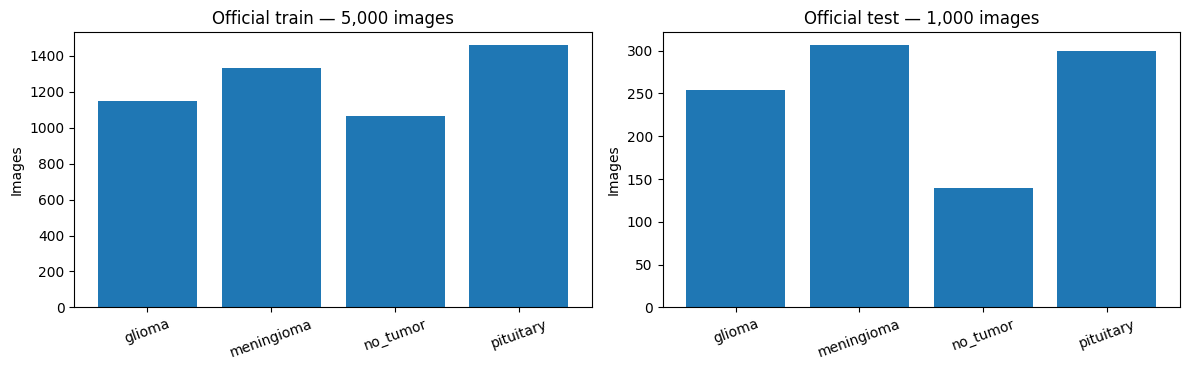

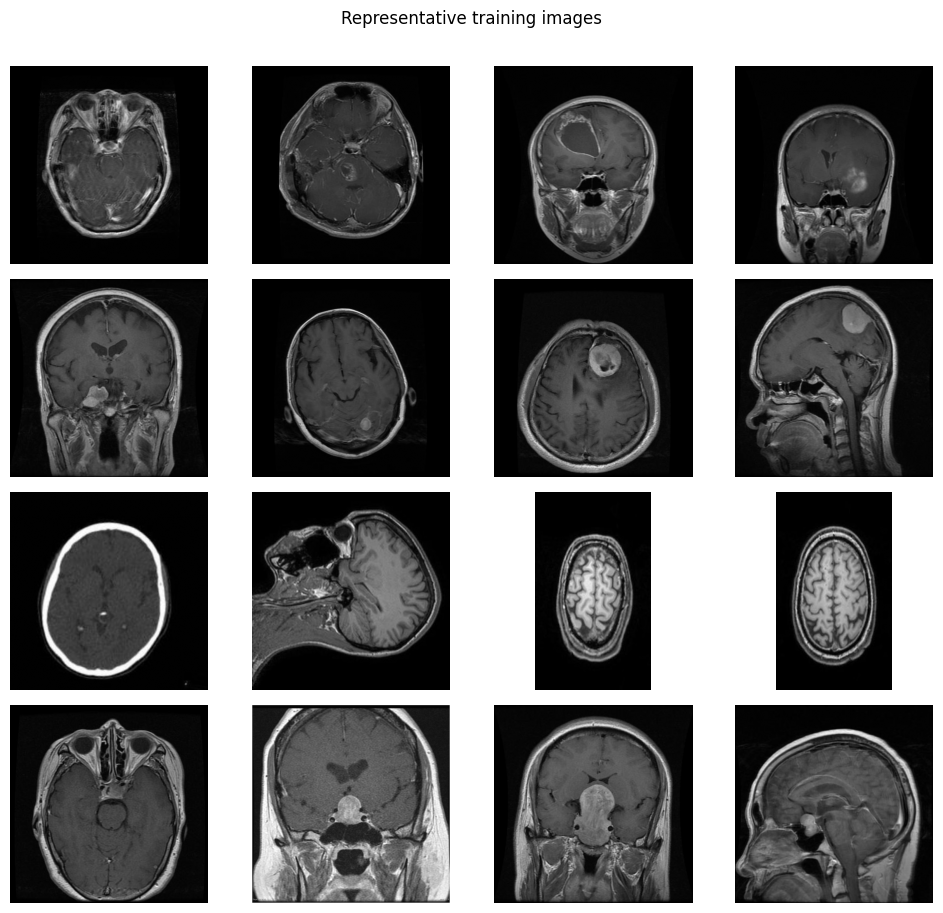

Train counts: {'glioma': 1147, 'meningioma': 1329, 'no_tumor': 1067, 'pituitary': 1457}
Test counts : {'glioma': 254, 'meningioma': 306, 'no_tumor': 140, 'pituitary': 300}


In [ ]:
# Collect the official train/test files in a stable order.
train_files, test_files = [], []
for class_name in CLASSES:
    train_files.extend(
        (p, class_name) for p in sorted((DATA / "classification_task" / "train" / class_name).glob("*.jpg"))
    )
    test_files.extend(
        (p, class_name) for p in sorted((DATA / "classification_task" / "test" / class_name).glob("*.jpg"))
    )

if not train_files or not test_files:
    raise RuntimeError("No classification images were found. Check the dataset directory structure.")

train_counts = Counter(label for _, label in train_files)
test_counts = Counter(label for _, label in test_files)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, counts, title in zip(axes, [train_counts, test_counts], ["Official train", "Official test"]):
    ax.bar(CLASSES, [counts[c] for c in CLASSES])
    ax.set_title(f"{title} — {sum(counts.values()):,} images")
    ax.set_ylabel("Images")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

rng = random.Random(SEED)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(10, 9))
for row, class_name in enumerate(CLASSES):
    candidates_for_class = [p for p, label in train_files if label == class_name]
    samples = rng.sample(candidates_for_class, k=min(4, len(candidates_for_class)))
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(samples):
            with Image.open(samples[col]) as im:
                ax.imshow(im.convert("L"), cmap="gray")
            if col == 0:
                ax.set_ylabel(class_name, fontsize=10)
plt.suptitle("Representative training images", y=1.01)
plt.tight_layout()
plt.show()

print("Train counts:", dict(train_counts))
print("Test counts :", dict(test_counts))

### Image properties and anatomical planes

This section checks image dimensions/modes and examines pixel intensities. Plane labels are parsed from the documented filename pattern `brisc2025_<split>_<index>_<tumor_code>_<plane_code>_<sequence>.jpg`. If the filenames differ in a future release, inspect the parsed codes before relying on plane-level summaries.

Most common image sizes: [((512, 512), 4120), ((369, 369), 323), ((216, 369), 277), ((256, 256), 27), ((187, 369), 21), ((202, 369), 19), ((225, 225), 13), ((210, 369), 12)]
Non-square images: 483 (9.7%) -> padded to square before resizing
Image modes: {'RGB': 2716, 'L': 2284}


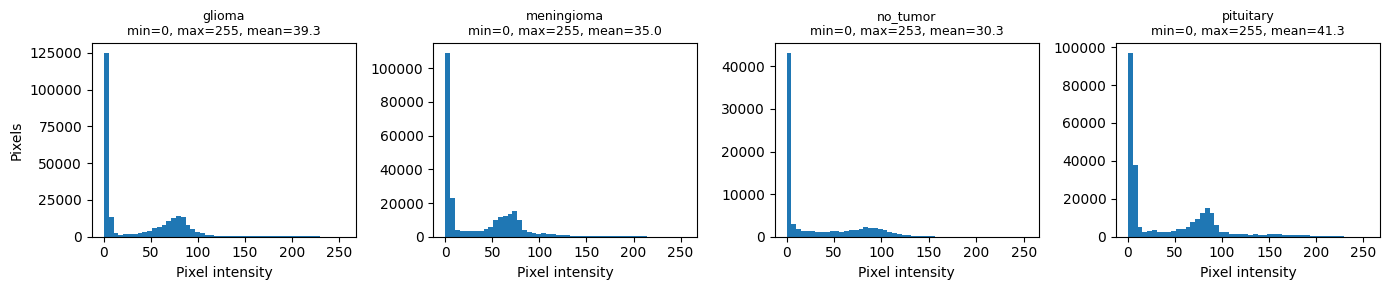


Train image counts by directory class and filename plane:


plane,axial,coronal,sagittal
class,,,
glioma,394,430,323
meningioma,423,426,480
no_tumor,352,310,405
pituitary,426,510,521



Filename tumor codes by directory class (audit only):


filename_tumor_code,gl,me,no,pi
class,,,,
glioma,1147,0,0,0
meningioma,0,1329,0,0
no_tumor,0,0,1067,0
pituitary,0,0,0,1457


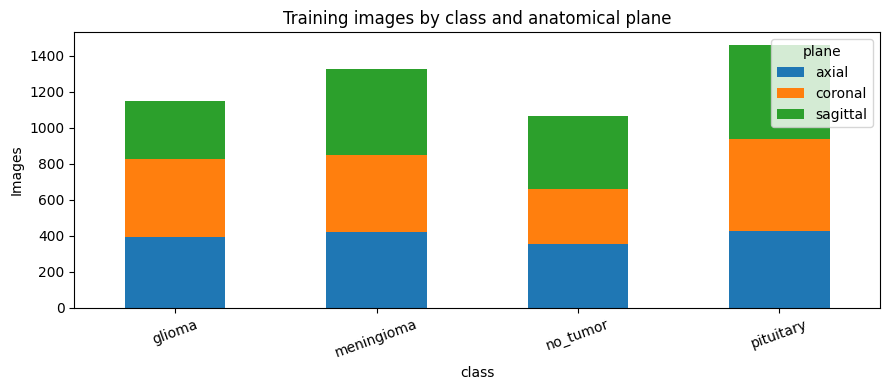

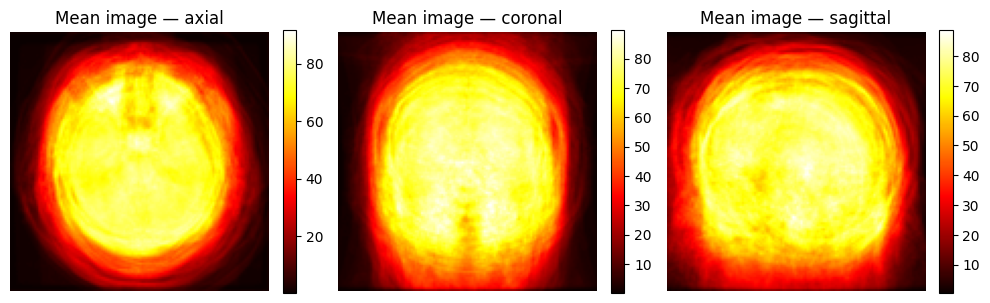

In [ ]:
# Inspect image dimensions and modes over the whole training split (only headers are read).
sizes, modes_seen = [], []
for path, _ in train_files:
    with Image.open(path) as im:
        sizes.append(im.size)  # (width, height)
        modes_seen.append(im.mode)
non_square = sum(w != h for w, h in sizes)
print("Most common image sizes:", Counter(sizes).most_common(8))
print(f"Non-square images: {non_square} ({100 * non_square / len(sizes):.1f}%) -> padded to square before resizing")
print("Image modes:", dict(Counter(modes_seen)))

# Pixel intensity distributions: one image per class.
fig, axes = plt.subplots(1, len(CLASSES), figsize=(14, 3))
for ax, class_name in zip(axes, CLASSES):
    path = next(p for p, label in train_files if label == class_name)
    with Image.open(path) as im:
        arr = np.asarray(im.convert("L"))
    ax.hist(arr.ravel(), bins=50)
    ax.set_title(f"{class_name}\nmin={arr.min()}, max={arr.max()}, mean={arr.mean():.1f}", fontsize=9)
    ax.set_xlabel("Pixel intensity")
axes[0].set_ylabel("Pixels")
plt.tight_layout()
plt.show()

PLANE_LABELS = {"ax": "axial", "co": "coronal", "sa": "sagittal"}

def filename_tokens(path):
    parts = path.stem.split("_")
    return {
        "tumor_code": parts[3] if len(parts) > 3 else "unknown",
        "plane_code": parts[4] if len(parts) > 4 else "unknown",
    }

def plane_of(path):
    code = filename_tokens(path)["plane_code"]
    return PLANE_LABELS.get(code, f"unknown ({code})")

plane_rows = []
for path, class_name in train_files:
    tokens = filename_tokens(path)
    plane_rows.append({
        "class": class_name,
        "plane": PLANE_LABELS.get(tokens["plane_code"], f"unknown ({tokens['plane_code']})"),
        "filename_tumor_code": tokens["tumor_code"],
    })
plane_df = pd.DataFrame(plane_rows)
print("\nTrain image counts by directory class and filename plane:")
plane_table = pd.crosstab(plane_df["class"], plane_df["plane"])
display(plane_table)
print("\nFilename tumor codes by directory class (audit only):")
display(pd.crosstab(plane_df["class"], plane_df["filename_tumor_code"]))

plane_table.plot(kind="bar", stacked=True, figsize=(9, 4))
plt.title("Training images by class and anatomical plane")
plt.ylabel("Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Average intensity maps by plane. These are visual summaries, not anatomical templates.
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, plane_code in zip(axes, ["ax", "co", "sa"]):
    pool = [p for p, _ in train_files if filename_tokens(p)["plane_code"] == plane_code]
    if not pool:
        ax.set_title(f"No samples: {plane_code}")
        ax.axis("off")
        continue
    chosen = rng.sample(pool, k=min(100, len(pool)))
    resized = []
    for path in chosen:
        with Image.open(path) as im:
            resized.append(np.asarray(im.convert("L").resize((128, 128)), dtype=np.float32))
    mean_img = np.mean(resized, axis=0)
    artist = ax.imshow(mean_img, cmap="hot")
    ax.set_title(f"Mean image — {PLANE_LABELS[plane_code]}")
    ax.axis("off")
    fig.colorbar(artist, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 3. Duplicate images between train and test

While exploring the data we noticed that some test images look identical to training images. A model can score well on such images just by remembering them, so we measure how many there are and remove them.

**Similarity measure.** Each image is padded to a square, resized to 32×32 and flattened to a vector. For two images $x, y$ with $n$ pixels, the Pearson correlation is

$$r(x,y)=\frac{1}{n}\sum_{i=1}^{n}\frac{(x_i-\bar{x})(y_i-\bar{y})}{\sigma_x\,\sigma_y}$$

$r = 1$ means identical up to brightness/contrast. We also compare against the mirrored image and keep the larger value.

**Why this is not chance.**
1. Two unrelated images have a low $r$ (see the random-pair numbers below).
2. Yet a large share of test images have a training image with $r > 0.95$, many with $r \approx 1$.
3. If such matches were coincidences, the two labels would agree only with probability $\sum_c p_c^2 \approx 25\%$; for the matches found, they agree almost always.

Random pairs of train images : median r = 0.53 | share with r > 0.95: 0.02%
Test images with a train image at r > 0.95: 776 of 1000 (77.6%); with r > 0.99: 570
Label agreement of matched pairs: expected by chance 25% | observed 99.5%


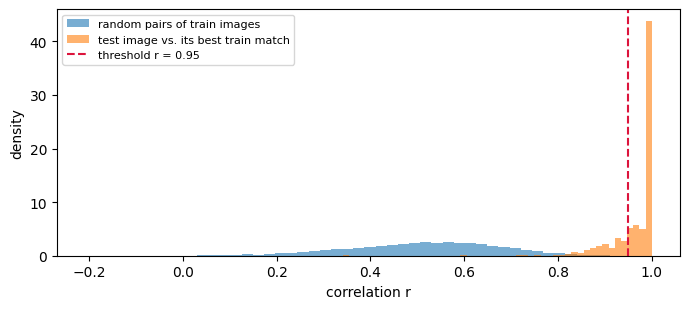

In [ ]:
FP_SIZE = 32
DUP_THRESH = 0.95
RESAMPLE = getattr(Image, "Resampling", Image)


def pad_to_square(image, fill=0):
    """Grayscale + zero-pad to a square canvas (keeps the aspect ratio when resizing)."""
    image = image.convert("L")
    width, height = image.size
    if width == height:
        return image
    side = max(width, height)
    canvas = Image.new("L", (side, side), fill)
    canvas.paste(image, ((side - width) // 2, (side - height) // 2))
    return canvas


def load_square(path):
    with Image.open(path) as im:
        return pad_to_square(im)


def fingerprint(path):
    small = load_square(path).resize((FP_SIZE, FP_SIZE), RESAMPLE.BILINEAR)
    v = np.asarray(small, dtype=np.float32).ravel()
    v = (v - v.mean()) / (v.std() + 1e-6)
    return v / np.sqrt(v.size)              # dot product of two fingerprints = Pearson r


def fingerprints(files):
    with ThreadPoolExecutor(max_workers=8) as pool:
        return np.stack(list(tqdm(pool.map(lambda item: fingerprint(item[0]), files),
                                  total=len(files), leave=False)))


def similarity(a, b):
    """r between every row of a and every row of b; best of 'as is' and 'a mirrored'."""
    a_mirrored = np.ascontiguousarray(a.reshape(-1, FP_SIZE, FP_SIZE)[:, :, ::-1]).reshape(len(a), -1)
    return np.maximum(a @ b.T, a_mirrored @ b.T)


fp_train, fp_test = fingerprints(train_files), fingerprints(test_files)
y_train_all = np.array([CLASS_TO_IDX[c] for _, c in train_files])
y_test_all = np.array([CLASS_TO_IDX[c] for _, c in test_files])

S = similarity(fp_test, fp_train)           # (n_test, n_train)
best_idx, best_r = S.argmax(axis=1), S.max(axis=1)

# 1) unrelated images: random pairs of training images
pairs = np.random.default_rng(SEED).integers(0, len(train_files), size=(20000, 2))
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
r_random = np.einsum("ij,ij->i", fp_train[pairs[:, 0]], fp_train[pairs[:, 1]])
print(f"Random pairs of train images : median r = {np.median(r_random):.2f} | "
      f"share with r > {DUP_THRESH}: {(r_random > DUP_THRESH).mean():.2%}")

# 2) test images that have a near-copy in train
has_match = best_r > DUP_THRESH
print(f"Test images with a train image at r > {DUP_THRESH}: {has_match.sum()} of {len(test_files)} "
      f"({has_match.mean():.1%}); with r > 0.99: {(best_r > 0.99).sum()}")

# 3) do the labels of the matched pairs agree?
class_freq = np.bincount(y_train_all) / len(y_train_all)
chance_agreement = float((class_freq ** 2).sum())
observed_agreement = float((y_train_all[best_idx[has_match]] == y_test_all[has_match]).mean())
print(f"Label agreement of matched pairs: expected by chance {chance_agreement:.0%} | observed {observed_agreement:.1%}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(r_random, bins=50, density=True, alpha=0.6, label="random pairs of train images")
ax.hist(best_r, bins=50, density=True, alpha=0.6, label="test image vs. its best train match")
ax.axvline(DUP_THRESH, color="crimson", linestyle="--", label=f"threshold r = {DUP_THRESH}")
ax.set_xlabel("correlation r"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

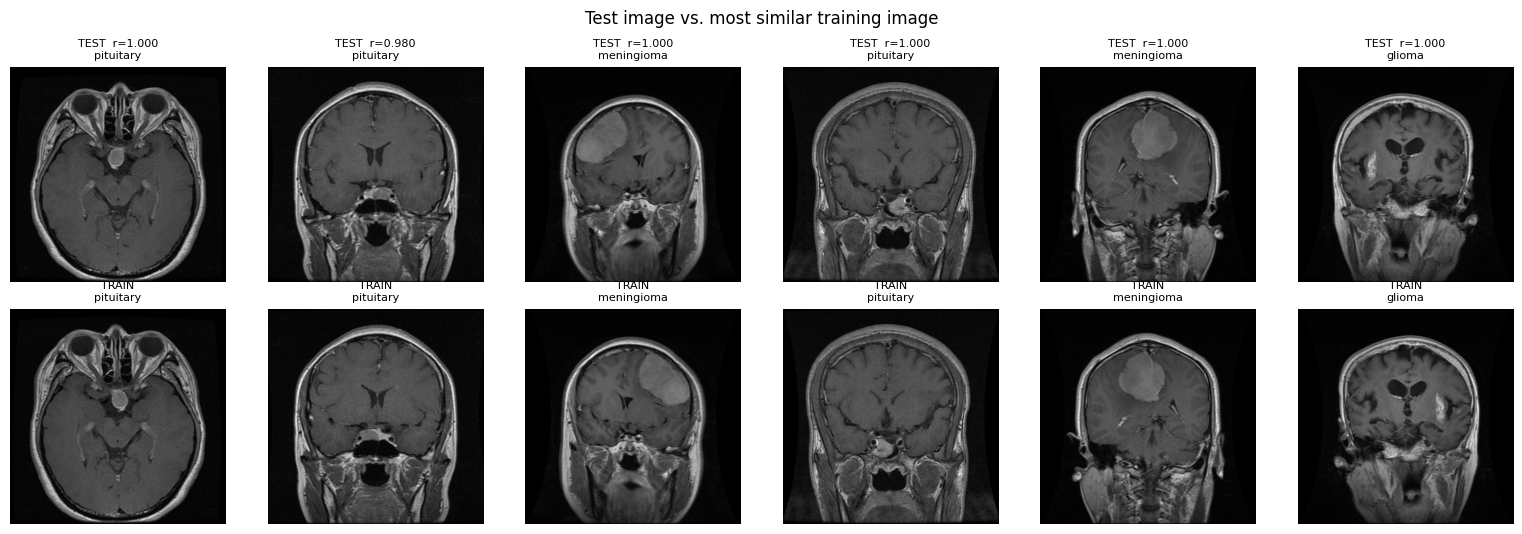

In [ ]:
# Random test images with r > 0.98 (top) and their most similar training image (bottom).
candidates = np.where(best_r > 0.98)[0]
pick = np.random.default_rng(SEED).choice(candidates, size=min(6, len(candidates)), replace=False)
fig, axes = plt.subplots(2, len(pick), figsize=(2.6 * len(pick), 5.4), squeeze=False)
for col, i in enumerate(pick):
    (test_path, test_class), (train_path, train_class) = test_files[i], train_files[best_idx[i]]
    axes[0, col].imshow(load_square(test_path), cmap="gray")
    axes[1, col].imshow(load_square(train_path), cmap="gray")
    axes[0, col].set_title(f"TEST  r={best_r[i]:.3f}\n{test_class}", fontsize=8)
    axes[1, col].set_title(f"TRAIN\n{train_class}", fontsize=8)
    axes[0, col].axis("off"); axes[1, col].axis("off")
plt.suptitle("Test image vs. most similar training image")
plt.tight_layout()
plt.show()

### Removing the duplicates

Every training image with $r > 0.95$ to **any** test image is removed. The official test set is left untouched. Near-copies *inside* the training set are put in the same group, so they end up together in either train or validation (section 4). This is a practical cleaning step, not a guarantee of patient-level independence.

In [ ]:
is_copy_of_test = (S > DUP_THRESH).any(axis=0)
removed = [f for f, d in zip(train_files, is_copy_of_test) if d]
print(f"Removed from train: {len(removed)} of {len(train_files)} images "
      f"({100 * len(removed) / len(train_files):.0f}%)  {dict(Counter(c for _, c in removed))}")

train_files = [f for f, d in zip(train_files, is_copy_of_test) if not d]
fp_train = fp_train[~is_copy_of_test]
print(f"Remaining train images: {len(train_files)} | official test images: {len(test_files)}")

# Group near-copies inside the remaining train set (used for the validation split).
S_train = similarity(fp_train, fp_train)
np.fill_diagonal(S_train, 0)
_, train_group_ids = connected_components(csr_matrix(S_train > DUP_THRESH), directed=False)
del S_train

Removed from train: 1746 of 5000 images (35%)  {'glioma': 336, 'meningioma': 508, 'no_tumor': 67, 'pituitary': 835}
Remaining train images: 3254 | official test images: 1000


## 4. Preprocessing and data loaders

Images are padded to a square canvas (some BRISC slices are not square), resized to `128 x 128`, and standardized independently with a per-image z-score. Training-only augmentation: small rotations, mild zoom, brightness/contrast jitter and left-right flips (not applied to sagittal slices, where mirroring would swap front and back).

A stratified validation subset (about 14%) is drawn **only from the cleaned training split**. Near-copies found above stay together, so validation images are not near-copies of training images. The official test split remains separate.

Class weights are computed from the *training subset only* so that validation labels do not contribute to training configuration.

Train: 2,779 | validation: 475 | official test: 1,000
Validation class counts: {'glioma': 114, 'meningioma': 121, 'no_tumor': 139, 'pituitary': 101}
Class weights: {'glioma': 0.997, 'meningioma': 0.993, 'no_tumor': 0.807, 'pituitary': 1.333}
Batch shape: (32, 1, 128, 128) | dtype: torch.float32
Batch mean: -0.000 | batch std: 1.000
Example labels: ['no_tumor', 'glioma', 'meningioma', 'glioma', 'meningioma', 'meningioma', 'pituitary', 'glioma']


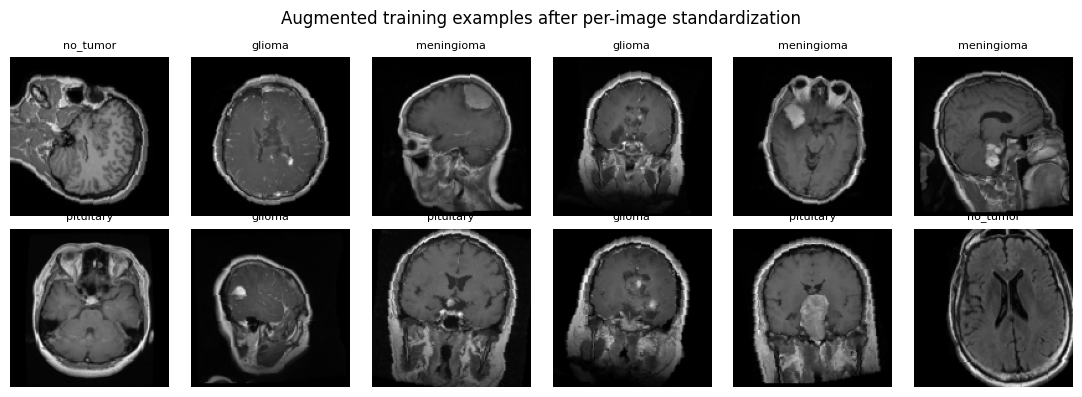

In [ ]:
def zscore(tensor):
    return (tensor - tensor.mean()) / (tensor.std(unbiased=False) + 1e-6)


def make_transform(train):
    ops = [transforms.Lambda(pad_to_square), transforms.Resize((IMG_SIZE, IMG_SIZE))]
    if train:
        ops += [
            transforms.RandomRotation(degrees=10),
            transforms.RandomAffine(degrees=0, scale=(0.95, 1.05)),
            transforms.ColorJitter(brightness=0.1, contrast=0.1),
        ]
    ops += [transforms.ToTensor(), transforms.Lambda(zscore)]
    return transforms.Compose(ops)


def plane_code_of(path):
    parts = Path(path).stem.split("_")
    return parts[4] if len(parts) > 4 else "unknown"


class MRIDataset(Dataset):
    def __init__(self, items, transform, augment_flip=False):
        self.items = items
        self.transform = transform
        self.augment_flip = augment_flip

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        path, label = self.items[index]
        with Image.open(path) as image:
            image = image.convert("L")
        # Mirror augmentation, skipped for sagittal slices.
        if self.augment_flip and plane_code_of(path) != "sa" and torch.rand(1).item() < 0.5:
            image = TF.hflip(image)
        return self.transform(image), int(label)


indexed_train = [(path, CLASS_TO_IDX[class_name]) for path, class_name in train_files]
indexed_test = [(path, CLASS_TO_IDX[class_name]) for path, class_name in test_files]
train_labels = np.array([label for _, label in indexed_train])

# Group-aware stratified split: about 1/7 of the cleaned train set becomes validation.
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(np.zeros(len(train_labels)), train_labels, groups=train_group_ids))
train_indexed = [indexed_train[i] for i in train_idx]
val_indexed = [indexed_train[i] for i in val_idx]

train_ds = MRIDataset(train_indexed, make_transform(train=True), augment_flip=True)
val_ds = MRIDataset(val_indexed, make_transform(train=False))
test_ds = MRIDataset(indexed_test, make_transform(train=False))

train_generator = torch.Generator().manual_seed(SEED)
loader_common = {
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
    "worker_init_fn": seed_worker,
}
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, **loader_common)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, **loader_common)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, **loader_common)

train_subset_labels = np.array([label for _, label in train_indexed])
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_subset_labels,
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)

print(f"Train: {len(train_ds):,} | validation: {len(val_ds):,} | official test: {len(test_ds):,}")
print("Validation class counts:", {CLASSES[k]: int(v) for k, v in
                                    zip(*np.unique([l for _, l in val_indexed], return_counts=True))})
print("Class weights:", {name: round(float(weight), 3) for name, weight in zip(CLASSES, class_weights_np)})

# Sanity check: dimensions, dtype, labels, and approximate normalization.
xb, yb = next(iter(train_loader))
print("Batch shape:", tuple(xb.shape), "| dtype:", xb.dtype)
print(f"Batch mean: {xb.mean().item():.3f} | batch std: {xb.std().item():.3f}")
print("Example labels:", [CLASSES[int(y)] for y in yb[:8]])

fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, image, label in zip(axes.flat, xb, yb):
    ax.imshow(image[0].cpu(), cmap="gray")
    ax.set_title(CLASSES[int(label)], fontsize=8)
    ax.axis("off")
plt.suptitle("Augmented training examples after per-image standardization")
plt.tight_layout()
plt.show()

## 5. Training utilities

Both models use the same training/validation split and the same evaluation protocol. The checkpoint with the highest **validation macro F1** is retained; early stopping and learning-rate scheduling use validation metrics only. The official test set is not used for model selection.

**Reproducibility.** Seeds are fixed, cuDNN/CUDA are set to deterministic mode, and adaptive average pooling is replaced by an equivalent plain mean (`GlobalAvgPool`), because the adaptive version has no deterministic CUDA backward. Each model is created right after `seed_everything`, so it starts from the same initial weights on every run; the printed *initial weight checksum* lets you verify this. For identical results, restart the runtime and use "Run all".

In [ ]:
def evaluate_classifier(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0
    total_count = 0
    all_labels, all_probs = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            if criterion is not None:
                total_loss += criterion(logits, labels).item() * labels.size(0)
            total_count += labels.size(0)
            all_labels.append(labels.cpu())
            all_probs.append(torch.softmax(logits, dim=1).cpu())

    y_true = torch.cat(all_labels).numpy()
    y_prob = torch.cat(all_probs).numpy()
    y_pred = y_prob.argmax(axis=1)
    mean_loss = total_loss / max(total_count, 1) if criterion is not None else np.nan
    metrics = {
        "loss": mean_loss,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }
    return metrics, y_true, y_pred, y_prob


def fit_model(model, train_loader, val_loader, *, epochs, patience, learning_rate,
              label_smoothing=0.0, weight_decay=1e-4):
    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=label_smoothing,
    )
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=2, factor=0.5
    )

    history = []
    best_state = None
    best_score = -np.inf
    best_metrics = None
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (logits.argmax(dim=1) == labels).sum().item()
            train_count += labels.size(0)

        train_loss = train_loss_sum / max(train_count, 1)
        train_accuracy = train_correct / max(train_count, 1)
        val_metrics, _, _, _ = evaluate_classifier(model, val_loader, criterion)
        scheduler.step(val_metrics["loss"])

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "train_accuracy": train_accuracy,
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
        })

        improved = val_metrics["macro_f1"] > best_score + 1e-6
        if improved:
            best_score = val_metrics["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            best_metrics = dict(val_metrics)
            epochs_without_improvement = 0
            marker = "  <- best validation macro F1"
        else:
            epochs_without_improvement += 1
            marker = ""

        print(
            f"Epoch {epoch:02d}/{epochs} | {time.time() - start:4.0f}s | "
            f"train loss {train_loss:.3f}, acc {train_accuracy:.3f} | "
            f"val loss {val_metrics['loss']:.3f}, acc {val_metrics['accuracy']:.3f}, "
            f"bal_acc {val_metrics['balanced_accuracy']:.3f}, "
            f"macro_F1 {val_metrics['macro_f1']:.3f}{marker}"
        )

        if epochs_without_improvement >= patience:
            print(f"Early stopping after {patience} epochs without validation macro-F1 improvement.")
            break

    if best_state is None:
        raise RuntimeError("Training did not produce a valid checkpoint.")
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_metrics


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["val_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["epoch"], history["train_accuracy"], label="train")
    axes[1].plot(history["epoch"], history["val_accuracy"], label="validation accuracy")
    axes[1].plot(history["epoch"], history["val_macro_f1"], label="validation macro F1")
    axes[1].set_title("Classification metrics")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [ ]:
class GlobalAvgPool(nn.Module):
    """Global average pooling as a plain mean (deterministic on GPU, unlike AdaptiveAvgPool2d)."""
    def forward(self, x):
        return x.mean(dim=(2, 3))


def weight_checksum(model):
    """Single number that identifies the model's weights; equal checksums = equal initial weights."""
    return sum(p.detach().double().sum().item() for p in model.parameters())


# ---- shared test-set evaluation (used by every model) ----
test_metrics_by_model = {}
test_planes = np.array([PLANE_LABELS.get(plane_code_of(p), "unknown") for p, _ in indexed_test])


def evaluate_on_test(model, name, cmap="Blues"):
    metrics, y_true, y_pred, y_prob = evaluate_classifier(
        model, test_loader, criterion=nn.CrossEntropyLoss()
    )
    try:
        macro_auc = roc_auc_score(
            y_true, y_prob, labels=np.arange(len(CLASSES)), multi_class="ovr", average="macro"
        )
    except ValueError as exc:
        print(f"Macro ROC-AUC unavailable: {exc}")
        macro_auc = np.nan
    test_metrics_by_model[name] = {**metrics, "macro_roc_auc_ovr": macro_auc}

    print(f"{name} - official test metrics")
    display(pd.DataFrame([{"model": name, **test_metrics_by_model[name]}]).round(4))

    print(f"\nClassification report - {name}")
    print(classification_report(
        y_true, y_pred, labels=np.arange(len(CLASSES)),
        target_names=CLASSES, digits=3, zero_division=0,
    ))

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASSES)))
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm, cmap=cmap)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=35, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"{name} - test confusion matrix")
    for row in range(len(CLASSES)):
        for col in range(len(CLASSES)):
            ax.text(col, row, str(cm[row, col]), ha="center", va="center",
                    color="white" if cm[row, col] > cm.max() / 2 else "black")
    fig.colorbar(image, ax=ax)
    plt.tight_layout()
    plt.show()

    plane_acc = (pd.DataFrame({"plane": test_planes, "correct": y_pred == y_true})
                 .groupby("plane")["correct"].agg(["mean", "count"]).round(3))
    print("Accuracy by anatomical plane:")
    display(plane_acc)

## 6. Model 1 — custom CNN baseline

This compact CNN is the from-scratch baseline. It provides a useful reference point before introducing ImageNet-pretrained features.

Trainable parameters: 97,908
Initial weight checksum: 247.529357
Epoch 01/30 |   11s | train loss 1.068, acc 0.520 | val loss 0.904, acc 0.640, bal_acc 0.631, macro_F1 0.630  <- best validation macro F1
Epoch 02/30 |    8s | train loss 0.830, acc 0.664 | val loss 0.735, acc 0.733, bal_acc 0.738, macro_F1 0.733  <- best validation macro F1
Epoch 03/30 |    9s | train loss 0.728, acc 0.703 | val loss 0.622, acc 0.756, bal_acc 0.756, macro_F1 0.749  <- best validation macro F1
Epoch 04/30 |    9s | train loss 0.697, acc 0.719 | val loss 0.568, acc 0.811, bal_acc 0.804, macro_F1 0.808  <- best validation macro F1
Epoch 05/30 |    9s | train loss 0.646, acc 0.746 | val loss 0.746, acc 0.709, bal_acc 0.700, macro_F1 0.694
Epoch 06/30 |    9s | train loss 0.612, acc 0.762 | val loss 0.576, acc 0.743, bal_acc 0.749, macro_F1 0.726
Epoch 07/30 |    9s | train loss 0.609, acc 0.769 | val loss 0.541, acc 0.783, bal_acc 0.782, macro_F1 0.776
Epoch 08/30 |    9s | train loss 0.569, acc 0.780 | val 

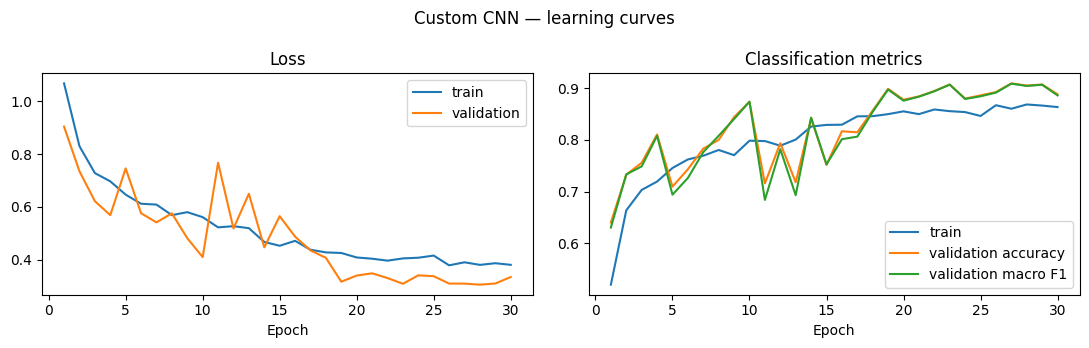

Best validation metrics: {'loss': 0.3089, 'accuracy': 0.9095, 'balanced_accuracy': 0.9063, 'macro_f1': 0.9089}


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(dropout),
        )

    def forward(self, x):
        return self.block(x)


class TumorCNN(nn.Module):
    def __init__(self, n_classes=len(CLASSES)):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 16),
            ConvBlock(16, 32),
            ConvBlock(32, 64, dropout=0.1),
            ConvBlock(64, 128, dropout=0.2),
        )
        self.pool = GlobalAvgPool()
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


seed_everything(SEED)                       # same initial weights on every run
cnn_model = TumorCNN().to(device)
print(f"Trainable parameters: {sum(p.numel() for p in cnn_model.parameters() if p.requires_grad):,}")
print(f"Initial weight checksum: {weight_checksum(cnn_model):.6f}")

seed_everything(SEED)                       # same batch order / augmentation on every run
train_loader.generator.manual_seed(SEED)
cnn_model, cnn_history, cnn_best = fit_model(
    cnn_model,
    train_loader,
    val_loader,
    epochs=30,
    patience=10,
    learning_rate=1e-3,
    label_smoothing=0.0,
)
plot_history(cnn_history, "Custom CNN — learning curves")
print("Best validation metrics:", {k: round(float(v), 4) for k, v in cnn_best.items()})
torch.save(cnn_model.state_dict(), CKPT_DIR / "cnn_baseline.pt")

Custom CNN - official test metrics


,model,loss,accuracy,balanced_accuracy,macro_f1,macro_roc_auc_ovr
0,Custom CNN,0.4905,0.815,0.8371,0.8128,0.9545



Classification report - Custom CNN
              precision    recall  f1-score   support

      glioma      0.941     0.752     0.836       254
  meningioma      0.728     0.663     0.694       306
    no_tumor      0.659     0.993     0.792       140
   pituitary      0.919     0.940     0.929       300

    accuracy                          0.815      1000
   macro avg      0.811     0.837     0.813      1000
weighted avg      0.829     0.815     0.814      1000



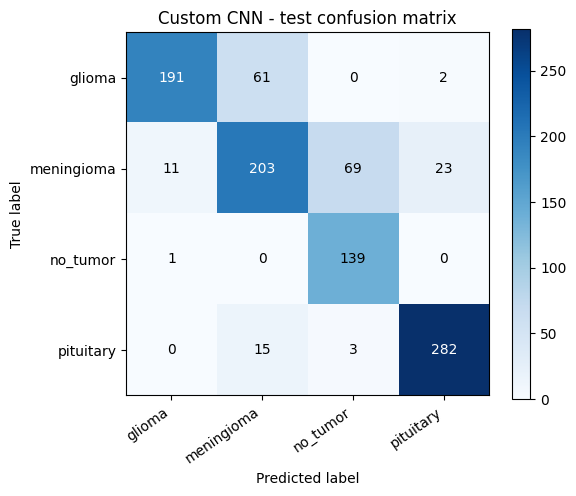

Accuracy by anatomical plane:


,mean,count
plane,,
axial,0.761,398
coronal,0.836,305
sagittal,0.865,297


In [ ]:
# Evaluate the custom CNN on the official test set.
evaluate_on_test(cnn_model, "Custom CNN", cmap="Blues")

## 7. Model 2 — transfer learning with ResNet18

ResNet18 starts from ImageNet-pretrained weights. Its first convolution is adapted from three input channels to one by averaging the pretrained RGB filters, and the final fully connected layer is replaced for the four BRISC classes. The full network is fine-tuned with a smaller learning rate.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Initial weight checksum: -12702.995517
Epoch 01/30 |   10s | train loss 0.630, acc 0.810 | val loss 0.450, acc 0.903, bal_acc 0.902, macro_F1 0.900  <- best validation macro F1
Epoch 02/30 |   10s | train loss 0.388, acc 0.938 | val loss 0.426, acc 0.918, bal_acc 0.919, macro_F1 0.915  <- best validation macro F1
Epoch 03/30 |   10s | train loss 0.336, acc 0.960 | val loss 0.430, acc 0.924, bal_acc 0.923, macro_F1 0.922  <- best validation macro F1
Epoch 04/30 |    9s | train loss 0.301, acc 0.974 | val loss 0.463, acc 0.914, bal_acc 0.910, macro_F1 0.911
Epoch 05/30 |   10s | train loss 0.285, acc 0.982 | val loss 0.425, acc 0.918, bal_acc 0.914, macro_F1 0.916
Epoch 06/30 |   10s | train loss 0.279, acc 0.985 | val loss 0.378, acc 0.937, bal_acc 0.936, macro_F1 0.935  <- best validation macro F1
Epoch 07/30 |   10s | train loss 0.258, acc 0.993 | val loss 0.380, acc 0.939, bal_acc 0.937, macro_F1 0.937  <- best validation macro F1
Epoch 08/30 |    9s | train loss 0.247, acc 0.994 | v

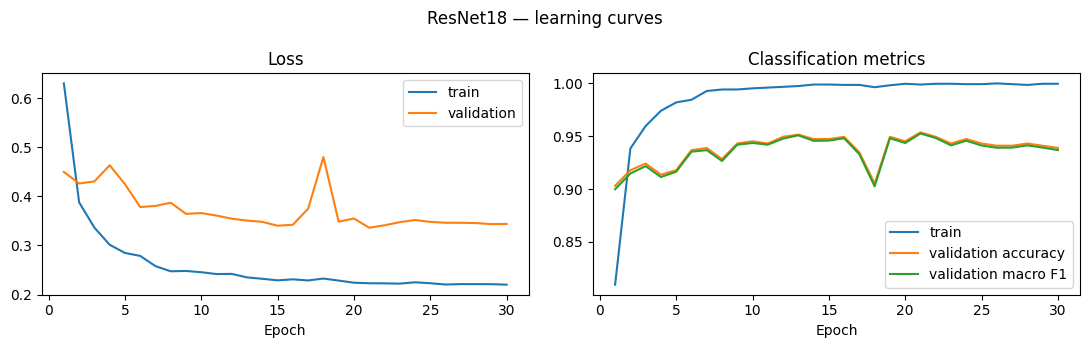

Best validation metrics: {'loss': 0.3361, 'accuracy': 0.9537, 'balanced_accuracy': 0.9527, 'macro_f1': 0.9526}


In [ ]:
seed_everything(SEED)                       # same initial weights on every run
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
old_conv = resnet_model.conv1
new_conv = nn.Conv2d(
    in_channels=1,
    out_channels=old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False,
)
with torch.no_grad():
    new_conv.weight.copy_(old_conv.weight.mean(dim=1, keepdim=True))
resnet_model.conv1 = new_conv
resnet_model.avgpool = GlobalAvgPool()      # deterministic replacement of the adaptive pooling
resnet_model.fc = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(resnet_model.fc.in_features, len(CLASSES)),
)
resnet_model = resnet_model.to(device)
print(f"Initial weight checksum: {weight_checksum(resnet_model):.6f}")

seed_everything(SEED)                       # same batch order / augmentation on every run
train_loader.generator.manual_seed(SEED)
resnet_model, resnet_history, resnet_best = fit_model(
    resnet_model,
    train_loader,
    val_loader,
    epochs=30,
    patience=10,
    learning_rate=1e-4,
    label_smoothing=0.05,
)
plot_history(resnet_history, "ResNet18 — learning curves")
print("Best validation metrics:", {k: round(float(v), 4) for k, v in resnet_best.items()})
torch.save(resnet_model.state_dict(), CKPT_DIR / "resnet18.pt")

ResNet18 transfer learning - official test metrics


,model,loss,accuracy,balanced_accuracy,macro_f1,macro_roc_auc_ovr
0,ResNet18 transfer learning,0.2078,0.933,0.9433,0.9317,0.9955



Classification report - ResNet18 transfer learning
              precision    recall  f1-score   support

      glioma      0.988     0.957     0.972       254
  meningioma      0.938     0.846     0.890       306
    no_tumor      0.838     1.000     0.912       140
   pituitary      0.936     0.970     0.953       300

    accuracy                          0.933      1000
   macro avg      0.925     0.943     0.932      1000
weighted avg      0.936     0.933     0.933      1000



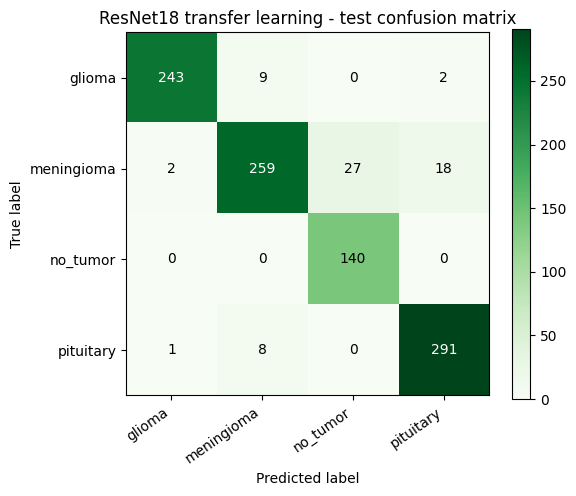

Accuracy by anatomical plane:


,mean,count
plane,,
axial,0.902,398
coronal,0.941,305
sagittal,0.966,297


In [ ]:
# Evaluate ResNet18 on the official test set.
evaluate_on_test(resnet_model, "ResNet18 transfer learning", cmap="Greens")

## 8. Compare Models

This is the final image-level evaluation for the model selected on validation data. After reviewing these results, avoid further architecture/hyperparameter tuning against this test set; use a new external dataset for another unbiased evaluation.

In [ ]:
test_comparison = pd.DataFrame([
    {"model": name, **metrics} for name, metrics in test_metrics_by_model.items()
]).set_index("model")[["accuracy", "balanced_accuracy", "macro_f1", "macro_roc_auc_ovr", "loss"]]

display(test_comparison.round(4))
test_comparison.round(4).to_csv("test_results.csv")

,accuracy,balanced_accuracy,macro_f1,macro_roc_auc_ovr,loss
model,,,,,
Custom CNN,0.815,0.8371,0.8128,0.9545,0.4905
ResNet18 transfer learning,0.933,0.9433,0.9317,0.9955,0.2078


## 9. Interpretation and limitations

- **Image-level evaluation:** BRISC provides 2D slices, and the public data lack reliable patient identifiers. The dataset paper describes manual efforts to reduce cross-split subject overlap but notes that subject-level independence cannot be guaranteed. Therefore, these scores should not be interpreted as patient-level diagnostic performance.
- **Duplicates:** many test images had identical or mirrored copies in the training split (section 3). Those training images were removed, so the models cannot score by memorizing them. The check uses a simple 32×32 correlation, so neighbouring slices of the same patient can remain; the test scores are probably still somewhat optimistic.
- **Validation vs. test:** validation scores are higher than test scores, which suggests that some neighbouring slices of the same patient still sit on both sides of the train/validation split. Report the test numbers, not the validation ones.
- **Potential shortcut learning:** class, plane, borders, contrast, or source-dataset artifacts can be predictive. Inspect errors and per-plane results, and consider cross-plane or external-dataset evaluation before making claims about generalization.
- **Single split and seed:** results are reproducible but come from one split and one training run per model.
- **Clinical use:** this notebook is for educational/research benchmarking only, not for diagnosis or clinical decision-making.

**Reference:** Fateh et al., *BRISC: Annotated Dataset for Brain Tumor Segmentation and Classification*, Scientific Data (2026). [Paper](https://www.nature.com/articles/s41597-026-06753-y) · [Dataset](https://www.kaggle.com/datasets/briscdataset/brisc2025/data)